# Bank Customer Churn Prediction — Master Notebook

**Problem:** Bir bankanin musterilerinin bankadan ayrilma (churn) davranisini analiz etmek ve tahmin etmek.

**Amac:**
- Musteri kaybini etkileyen demografik, davranissal ve finansal faktorleri analiz etmek
- Lojistik regresyon ile churn tahmini yapmak
- Risk segmentasyonu olusturarak aksiyon onerileri sunmak

**Veri Seti:** 10.000 banka musterisi, 12 degisken

---

## 1. Kutuphaneler ve Veri Yukleme

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print('Kutuphaneler yuklendi.')

Kutuphaneler yuklendi.


In [41]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print(f'Veri seti boyutu: {df.shape[0]:,} satir x {df.shape[1]} sutun')
df.head()

Saving Bank Customer Churn Prediction.csv to Bank Customer Churn Prediction (1).csv
Veri seti boyutu: 10,000 satir x 12 sutun


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


---
## 2. Veri Kalite Kontrolu

In [42]:
# Veri tipleri ve null kontrolu
info_df = pd.DataFrame({
    'Tip': df.dtypes,
    'Null': df.isnull().sum(),
    'Unique': df.nunique(),
    'Ornek': df.iloc[0]
})
print(f'Duplike satir: {df.duplicated().sum()}')
print(f'customer_id benzersiz mi: {df["customer_id"].nunique() == len(df)}')
print()
info_df

Duplike satir: 0
customer_id benzersiz mi: True



,Tip,Null,Unique,Ornek
customer_id,int64,0,10000,15634602
credit_score,int64,0,460,619
country,object,0,3,France
gender,object,0,2,Female
age,int64,0,70,42
tenure,int64,0,11,2
balance,float64,0,6382,0.00
products_number,int64,0,4,1
credit_card,int64,0,2,1
active_member,int64,0,2,1


Veri setinde eksik veya duplike veri bulunmamaktadir. Degisken tipleri analiz icin uygun yapidadir. customer_id her musteri icin benzersizdir (primary key).

In [43]:
# Temel istatistikler
df.describe().T[['count', 'mean', 'std', 'min', 'max']]

,count,mean,std,min,max
customer_id,10000.00,15690940.57,71936.19,15565701.00,15815690.00
credit_score,10000.00,650.53,96.65,350.00,850.00
age,10000.00,38.92,10.49,18.00,92.00
tenure,10000.00,5.01,2.89,0.00,10.00
balance,10000.00,76485.89,62397.41,0.00,250898.09
products_number,10000.00,1.53,0.58,1.00,4.00
credit_card,10000.00,0.71,0.46,0.00,1.00
active_member,10000.00,0.52,0.50,0.00,1.00
estimated_salary,10000.00,100090.24,57510.49,11.58,199992.48
churn,10000.00,0.20,0.40,0.00,1.00


- Ortalama yas: 39 — Orta yas musteri segmentine hitap ediyor
- Ortalama tenure: 5 — Dengeli dagilim
- Balance: Cok sayida musterinin bakiyesi 0 (25. yuzdelik = 0)
- Estimated salary: 11 ile 200K arasi genis dagilim

---
## 3. Degisken Dagilimlari

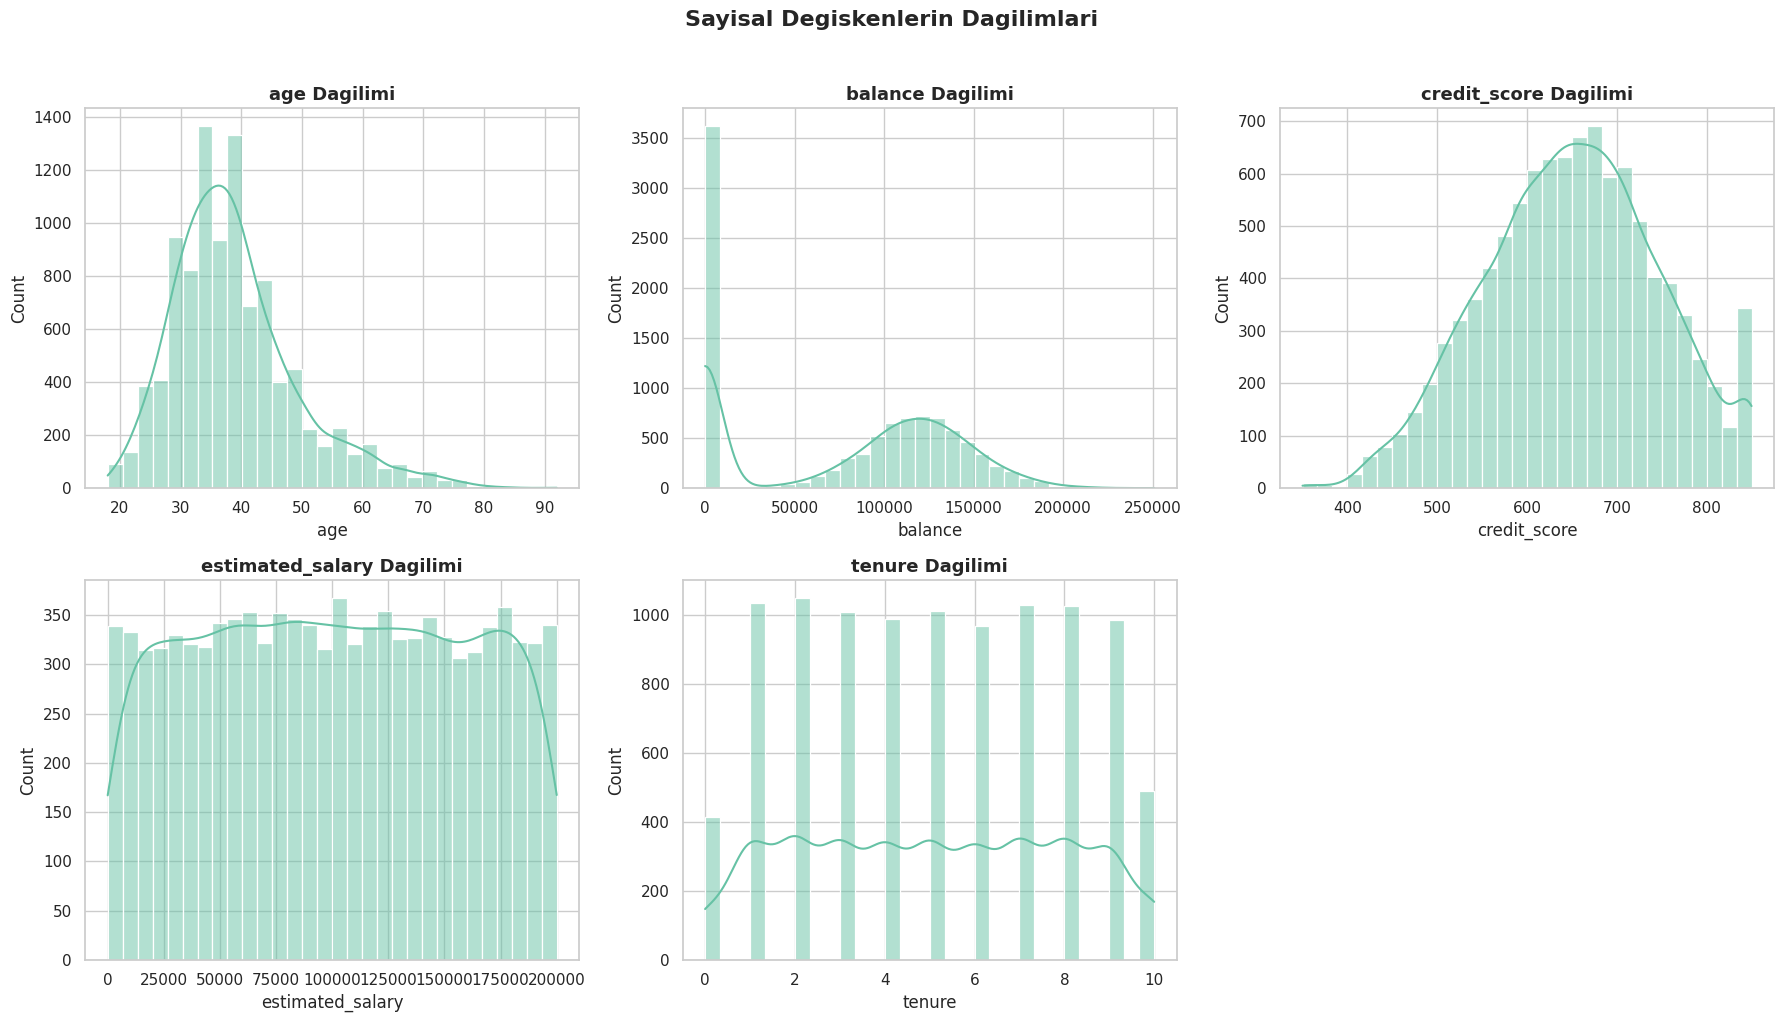

In [44]:
dist_cols = ['age', 'balance', 'credit_score', 'estimated_salary', 'tenure']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(dist_cols):
    sns.histplot(df[col], kde=True, bins=30, ax=axes[i])
    axes[i].set_title(f'{col} Dagilimi', fontsize=13, fontweight='bold')

axes[5].set_visible(False)
plt.suptitle('Sayisal Degiskenlerin Dagilimlari', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

- **Age:** 30-50 yas araliginda yogunlasma. Orta yas segment bankanin ana musteri kitlesini olusturuyor.
- **Balance:** Cok sayida musterinin bakiyesi 0. Bu durum bankayi aktif kullanmayan musteri segmentine isaret ediyor.
- **Credit Score:** 600-750 bandinda yogunlasma. Musteri kitlesi genel olarak orta risk profilinde.
- **Estimated Salary:** Genis ve dengeli dagilim, belirgin yogunlasma yok.
- **Tenure:** Ortalama ~5 yil, dengeli dagilim.

---
## 4. Overall KPI (Makro Seviye)

In [45]:
total_customers = df.shape[0]
churn_customers = df['churn'].sum()
churn_rate = churn_customers / total_customers

print(f'Toplam Musteri     : {total_customers:,}')
print(f'Ayrilan Musteri    : {churn_customers:,}')
print(f'Kalan Musteri      : {total_customers - churn_customers:,}')
print(f'Genel Churn Orani  : %{churn_rate*100:.1f}')

Toplam Musteri     : 10,000
Ayrilan Musteri    : 2,037
Kalan Musteri      : 7,963
Genel Churn Orani  : %20.4


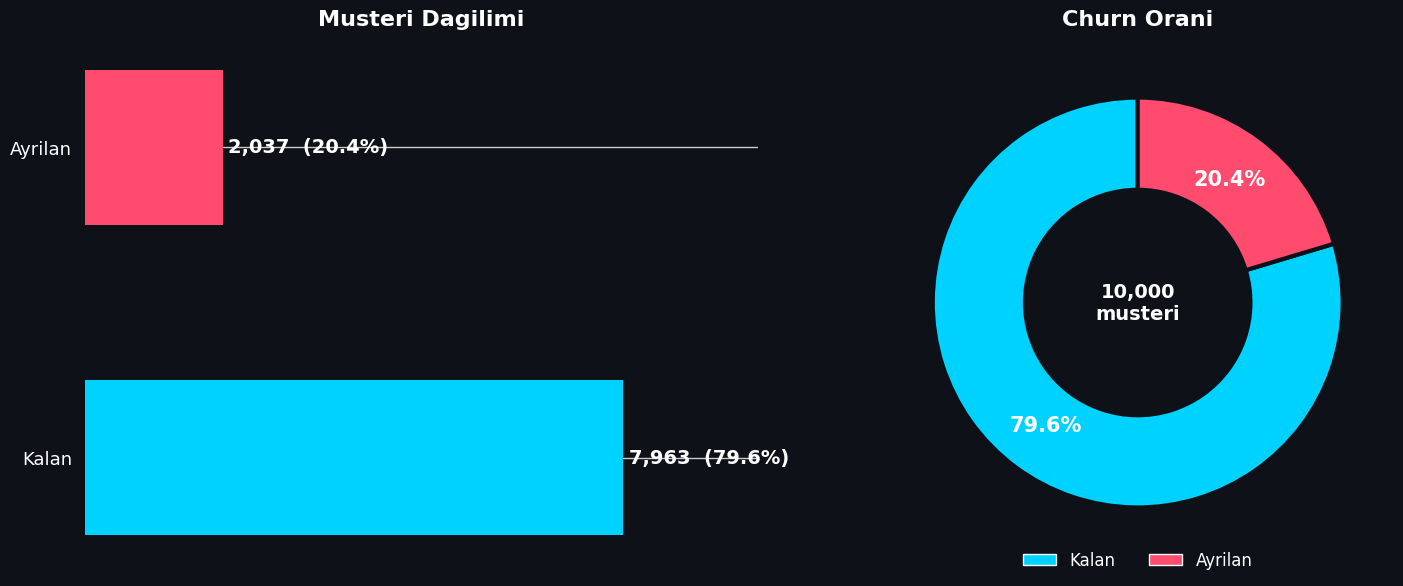

Her 5 musteriden 1'i ayrilmis. Yuksek sayilabilecek bir oran.


In [46]:
import matplotlib.patches as mpatches

churn_counts = df['churn'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), facecolor='#0e1117')

labels = ['Kalan', 'Ayrilan']
values = [churn_counts[0], churn_counts[1]]
colors = ['#00d2ff', '#ff4b6e']

# Yatay bar chart
bars = axes[0].barh(labels, values, color=colors, height=0.5, edgecolor='none', zorder=3)
axes[0].set_facecolor('#0e1117')
axes[0].set_xlim(0, max(values) * 1.25)
axes[0].spines[:].set_visible(False)
axes[0].tick_params(axis='both', colors='white', labelsize=13)
axes[0].xaxis.set_visible(False)
for bar, val in zip(bars, values):
    axes[0].text(bar.get_width() + 80, bar.get_y() + bar.get_height()/2,
                f'{val:,}  ({val/total_customers*100:.1f}%)',
                va='center', fontsize=14, fontweight='bold', color='white')
axes[0].set_title('Musteri Dagilimi', fontsize=16, fontweight='bold', color='white', pad=15)

# Donut chart
wedges, texts, autotexts = axes[1].pie(
    churn_counts.values, labels=None, autopct='%1.1f%%',
    colors=colors, startangle=90, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='#0e1117', linewidth=3),
    textprops={'fontsize': 15, 'fontweight': 'bold', 'color': 'white'})
axes[1].set_facecolor('#0e1117')
axes[1].text(0, 0, f'{total_customers:,}\nmusteri', ha='center', va='center',
            fontsize=14, fontweight='bold', color='white')
legend_elements = [mpatches.Patch(facecolor=c, label=l) for c, l in zip(colors, labels)]
axes[1].legend(handles=legend_elements, loc='lower center', fontsize=12,
              facecolor='#0e1117', edgecolor='none', labelcolor='white',
              ncol=2, bbox_to_anchor=(0.5, -0.05))
axes[1].set_title('Churn Orani', fontsize=16, fontweight='bold', color='white', pad=15)

plt.tight_layout()
plt.show()

print(f'Her 5 musteriden 1\'i ayrilmis. Yuksek sayilabilecek bir oran.')

---
## 5. Demografik KPI Analizi

Musterilerin ulke, cinsiyet ve yas gibi demografik ozelliklerine gore churn oranlarini inceliyoruz.

### 5.1 Country vs Churn

In [47]:
country_churn = df.groupby('country')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
country_churn['Churn_Orani_%'] = (country_churn['Churn_Orani'] * 100).round(2)
print(country_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

         Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
country                                             
France             5014           810          16.15
Germany            2509           814          32.44
Spain              2477           413          16.67


- **Almanya:** Churn orani %32.4 ile diger ulkelerin yaklasik 2 kati
- **Fransa:** %16.2
- **Ispanya:** %16.7

Almanya'da musteri kaybi ciddi bir problem.

### 5.2 Gender vs Churn

In [48]:
gender_churn = df.groupby('gender')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
gender_churn['Churn_Orani_%'] = (gender_churn['Churn_Orani'] * 100).round(2)
print(gender_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

        Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
gender                                             
Female            4543          1139          25.07
Male              5457           898          16.46


- **Kadin:** Churn %25.1
- **Erkek:** Churn %16.5

Kadin musteriler erkeklere gore ~1.5 kat daha fazla ayriliyor.

### 5.3 Age vs Churn

In [49]:
# Yas gruplari olustur
def age_segment(age):
    if age <= 32:
        return '18-32 (Young)'
    elif age <= 44:
        return '33-44 (Middle)'
    else:
        return '45+ (Senior)'

df['age_group'] = df['age'].apply(age_segment)

age_churn = df.groupby('age_group')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
age_churn['Churn_Orani_%'] = (age_churn['Churn_Orani'] * 100).round(2)
print(age_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

                Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
age_group                                                  
18-32 (Young)             2790           213           7.63
33-44 (Middle)            4870           780          16.02
45+ (Senior)              2340          1044          44.62


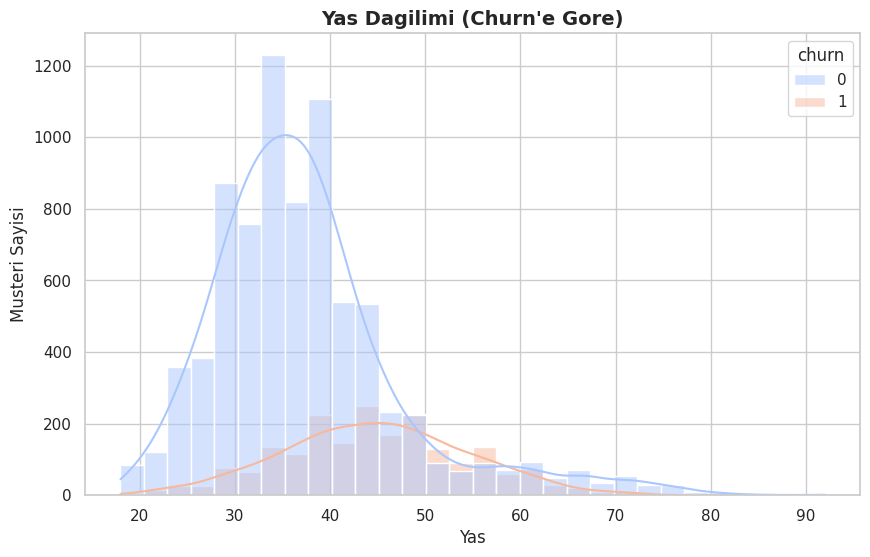

In [50]:
# Yasa gore churn gorsellestirme
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='age', hue='churn', kde=True, bins=30, palette='coolwarm')
plt.title('Yas Dagilimi (Churn\'e Gore)', fontsize=14, fontweight='bold')
plt.xlabel('Yas')
plt.ylabel('Musteri Sayisi')
plt.show()

- Yas arttikca churn dramatik bicimde artiyor
- 45+ yas grubunda churn orani ~%44.6 — neredeyse her 2 musteriden 1'i ayriliyor
- 18-32 yas grubunda churn sadece ~%7.5
- **Yas, churn'u en cok etkileyen demografik degisken**

---
## 6. Davranissal KPI Analizi

Musterilerin bankayi nasil kullandigina dair degiskenler: aktiflik, urun sayisi, kredi karti, tenure.

### 6.1 Active Member vs Churn

In [51]:
active_churn = df.groupby('active_member')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
active_churn.index = ['Pasif (0)', 'Aktif (1)']
active_churn['Churn_Orani_%'] = (active_churn['Churn_Orani'] * 100).round(2)
print(active_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

           Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
Pasif (0)            4849          1302          26.85
Aktif (1)            5151           735          14.27


- Pasif musteriler: Churn %26.9
- Aktif musteriler: Churn %14.3
- Pasif musteriler aktif musterilere gore ~2 kat daha fazla ayriliyor

### 6.2 Products Number vs Churn

In [19]:
products_churn = df.groupby('products_number')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
products_churn['Churn_Orani_%'] = (products_churn['Churn_Orani'] * 100).round(2)
print(products_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

                 Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
products_number                                             
1                          5084          1409          27.71
2                          4590           348           7.58
3                           266           220          82.71
4                            60            60         100.00


- 1 urun: %27.7 churn (5,084 musteri)
- 2 urun: %7.6 churn (4,590 musteri) — en sadik grup
- 3 urun: %82.7 churn (266 musteri)
- 4 urun: %100 churn (60 musteri)

2 urunlu musteriler en bagli segment. 3-4 urunlu musterilerin neredeyse tamami ayrilmis — bu kucuk ama cok yuksek riskli bir grup.

### 6.3 Credit Card vs Churn

In [20]:
cc_churn = df.groupby('credit_card')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
cc_churn.index = ['Yok (0)', 'Var (1)']
cc_churn['Churn_Orani_%'] = (cc_churn['Churn_Orani'] * 100).round(2)
print(cc_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

         Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
Yok (0)            2945           613          20.81
Var (1)            7055          1424          20.18


- Kredi karti olan: %20.2 churn
- Kredi karti olmayan: %20.8 churn
- **Kredi karti sahipliginin churn uzerinde anlamli bir etkisi yok.**

### 6.4 Tenure vs Churn

In [21]:
def tenure_group(x):
    if x <= 2:
        return '0-2 (New)'
    elif x <= 6:
        return '3-6 (Silver)'
    else:
        return '7-10 (Gold)'

df['tenure_group'] = df['tenure'].apply(tenure_group)

tenure_churn = df.groupby('tenure_group')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
tenure_churn['Churn_Orani_%'] = (tenure_churn['Churn_Orani'] * 100).round(2)
print(tenure_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

              Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
tenure_group                                             
0-2 (New)               2496           528          21.15
3-6 (Silver)            3977           821          20.64
7-10 (Gold)             3527           688          19.51


- New (0-2 yil): %21.2
- Silver (3-6 yil): %20.6
- Gold (7+ yil): %19.5

Tenure arttikca churn hafif azaliyor ama etki cok zayif. **Tenure'un churn uzerinde belirleyici bir etkisi yok.**

---
## 7. Finansal KPI Analizi

Balance, estimated salary ve credit score degiskenlerinin churn ile iliskisi.

### 7.1 Balance vs Churn

In [22]:
# Bakiye segmentleri
def balance_group(x):
    if x == 0:
        return 'Zero'
    elif x <= 100000:
        return 'Low (0-100K)'
    else:
        return 'High (100K+)'

df['balance_group'] = df['balance'].apply(balance_group)

balance_summary = df.groupby('balance_group')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
balance_summary['Churn_Orani_%'] = (balance_summary['Churn_Orani'] * 100).round(2)
print(balance_summary[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

print(f'\nKalan musteri ortalama bakiye: {df[df["churn"]==0]["balance"].mean():,.0f}')
print(f'Ayrilan musteri ortalama bakiye: {df[df["churn"]==1]["balance"].mean():,.0f}')

               Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
balance_group                                             
High (100K+)             4799          1211          25.23
Low (0-100K)             1584           326          20.58
Zero                     3617           500          13.82

Kalan musteri ortalama bakiye: 72,745
Ayrilan musteri ortalama bakiye: 91,109


- Bakiyesi 0 olan musteriler: %13.8 churn — en dusuk oran
- 100K+ bakiyeli musteriler: %25.2 churn — en yuksek oran
- Ayrilan musterilerin ortalama bakiyesi (91,109) kalanlardan (72,745) daha yuksek
- **Paradoks:** Bakiyesi yuksek musteriler daha cok ayriliyor — alternatifleri var ve baska bankaya kolayca gecebiliyorlar.

### 7.2 Estimated Salary vs Churn

In [23]:
print(f'Kalan musteri ortalama maas: {df[df["churn"]==0]["estimated_salary"].mean():,.0f}')
print(f'Ayrilan musteri ortalama maas: {df[df["churn"]==1]["estimated_salary"].mean():,.0f}')
print(f'Fark: {abs(df[df["churn"]==0]["estimated_salary"].mean() - df[df["churn"]==1]["estimated_salary"].mean()):,.0f}')

Kalan musteri ortalama maas: 99,738
Ayrilan musteri ortalama maas: 101,466
Fark: 1,727


- Kalan: 99,738 — Ayrilan: 101,466
- Sadece 1,728 fark — 100K'lik maaslarda bu %1.7'lik bir fark
- **Estimated salary'nin churn uzerinde hicbir etkisi yok.**

### 7.3 Credit Score vs Churn

In [24]:
def credit_segment(x):
    if x <= 600:
        return 'Low (350-600)'
    elif x <= 700:
        return 'Medium (601-700)'
    else:
        return 'High (701-850)'

df['credit_group'] = df['credit_score'].apply(credit_segment)

credit_churn = df.groupby('credit_group')['churn'].agg(
    Musteri_Sayisi='count',
    Churn_Sayisi='sum',
    Churn_Orani='mean'
).round(4)
credit_churn['Churn_Orani_%'] = (credit_churn['Churn_Orani'] * 100).round(2)
print(credit_churn[['Musteri_Sayisi', 'Churn_Sayisi', 'Churn_Orani_%']])

print(f'\nKalan musteri ortalama kredi skoru: {df[df["churn"]==0]["credit_score"].mean():.1f}')
print(f'Ayrilan musteri ortalama kredi skoru: {df[df["churn"]==1]["credit_score"].mean():.1f}')

                  Musteri_Sayisi  Churn_Sayisi  Churn_Orani_%
credit_group                                                 
High (701-850)              3116           619          19.87
Low (350-600)               3066           665          21.69
Medium (601-700)            3818           753          19.72

Kalan musteri ortalama kredi skoru: 651.9
Ayrilan musteri ortalama kredi skoru: 645.4


- Low: %21.7 — Medium: %19.7 — High: %19.9
- Segmentler arasi fark minimal
- **Kredi skorunun churn uzerinde belirleyici bir etkisi yok.**

---
## 8. Korelasyon Analizi

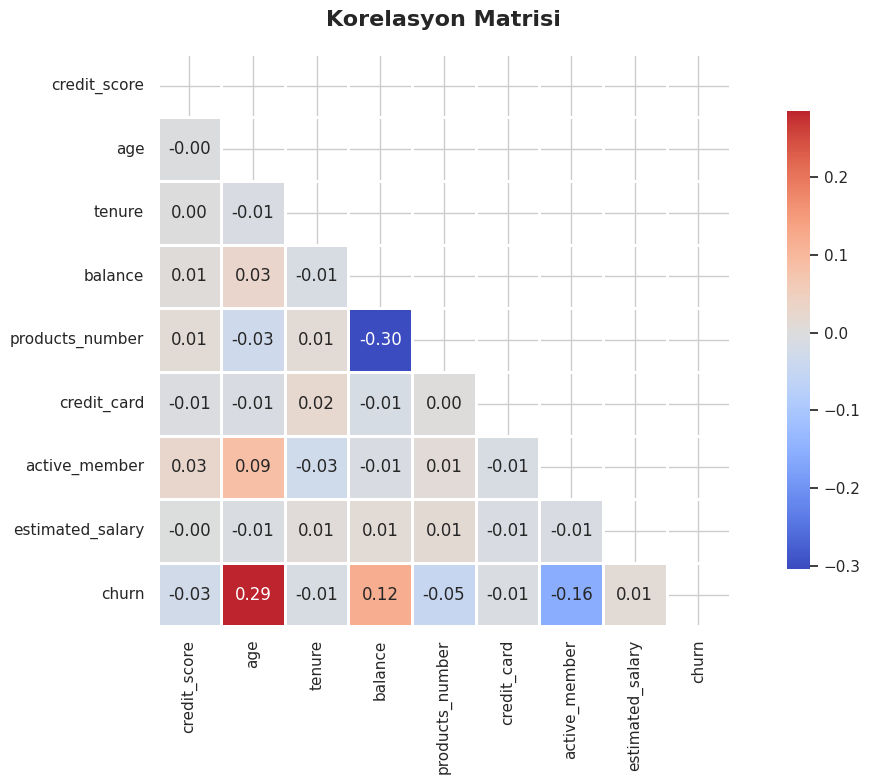


Churn ile Korelasyonlar (mutlak degere gore sirali):
  + age                 : +0.2853
  - active_member       : -0.1561
  + balance             : +0.1185
  - products_number     : -0.0478
  - credit_score        : -0.0271
  - tenure              : -0.0140
  + estimated_salary    : +0.0121
  - credit_card         : -0.0071


In [25]:
corr_cols = ['credit_score', 'age', 'tenure', 'balance', 'products_number',
             'credit_card', 'active_member', 'estimated_salary', 'churn']

corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Korelasyon Matrisi', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Churn ile korelasyonlar
print('\nChurn ile Korelasyonlar (mutlak degere gore sirali):')
churn_corr = corr_matrix['churn'].drop('churn').abs().sort_values(ascending=False)
for col, val in churn_corr.items():
    direction = '+' if corr_matrix.loc[col, 'churn'] > 0 else '-'
    print(f'  {direction} {col:20s}: {corr_matrix.loc[col, "churn"]:+.4f}')

- **age (+0.285):** En guclu korelasyon. Yas arttikca churn artiyor.
- **active_member (-0.156):** Aktif musteri daha az ayriliyor.
- **balance (+0.119):** Bakiyesi yuksek olan daha cok ayriliyor.
- **products_number (-0.048):** Korelasyon dusuk ama aldatici — dogrusal olmayan cok guclu etki var (2 urunde %7.6, 3 urunde %82.7).
- **credit_score, tenure, estimated_salary, credit_card:** Korelasyon neredeyse sifir — churn uzerinde etkisiz.

---
## 9. Churn'e Gore Karsilastirmali Analiz

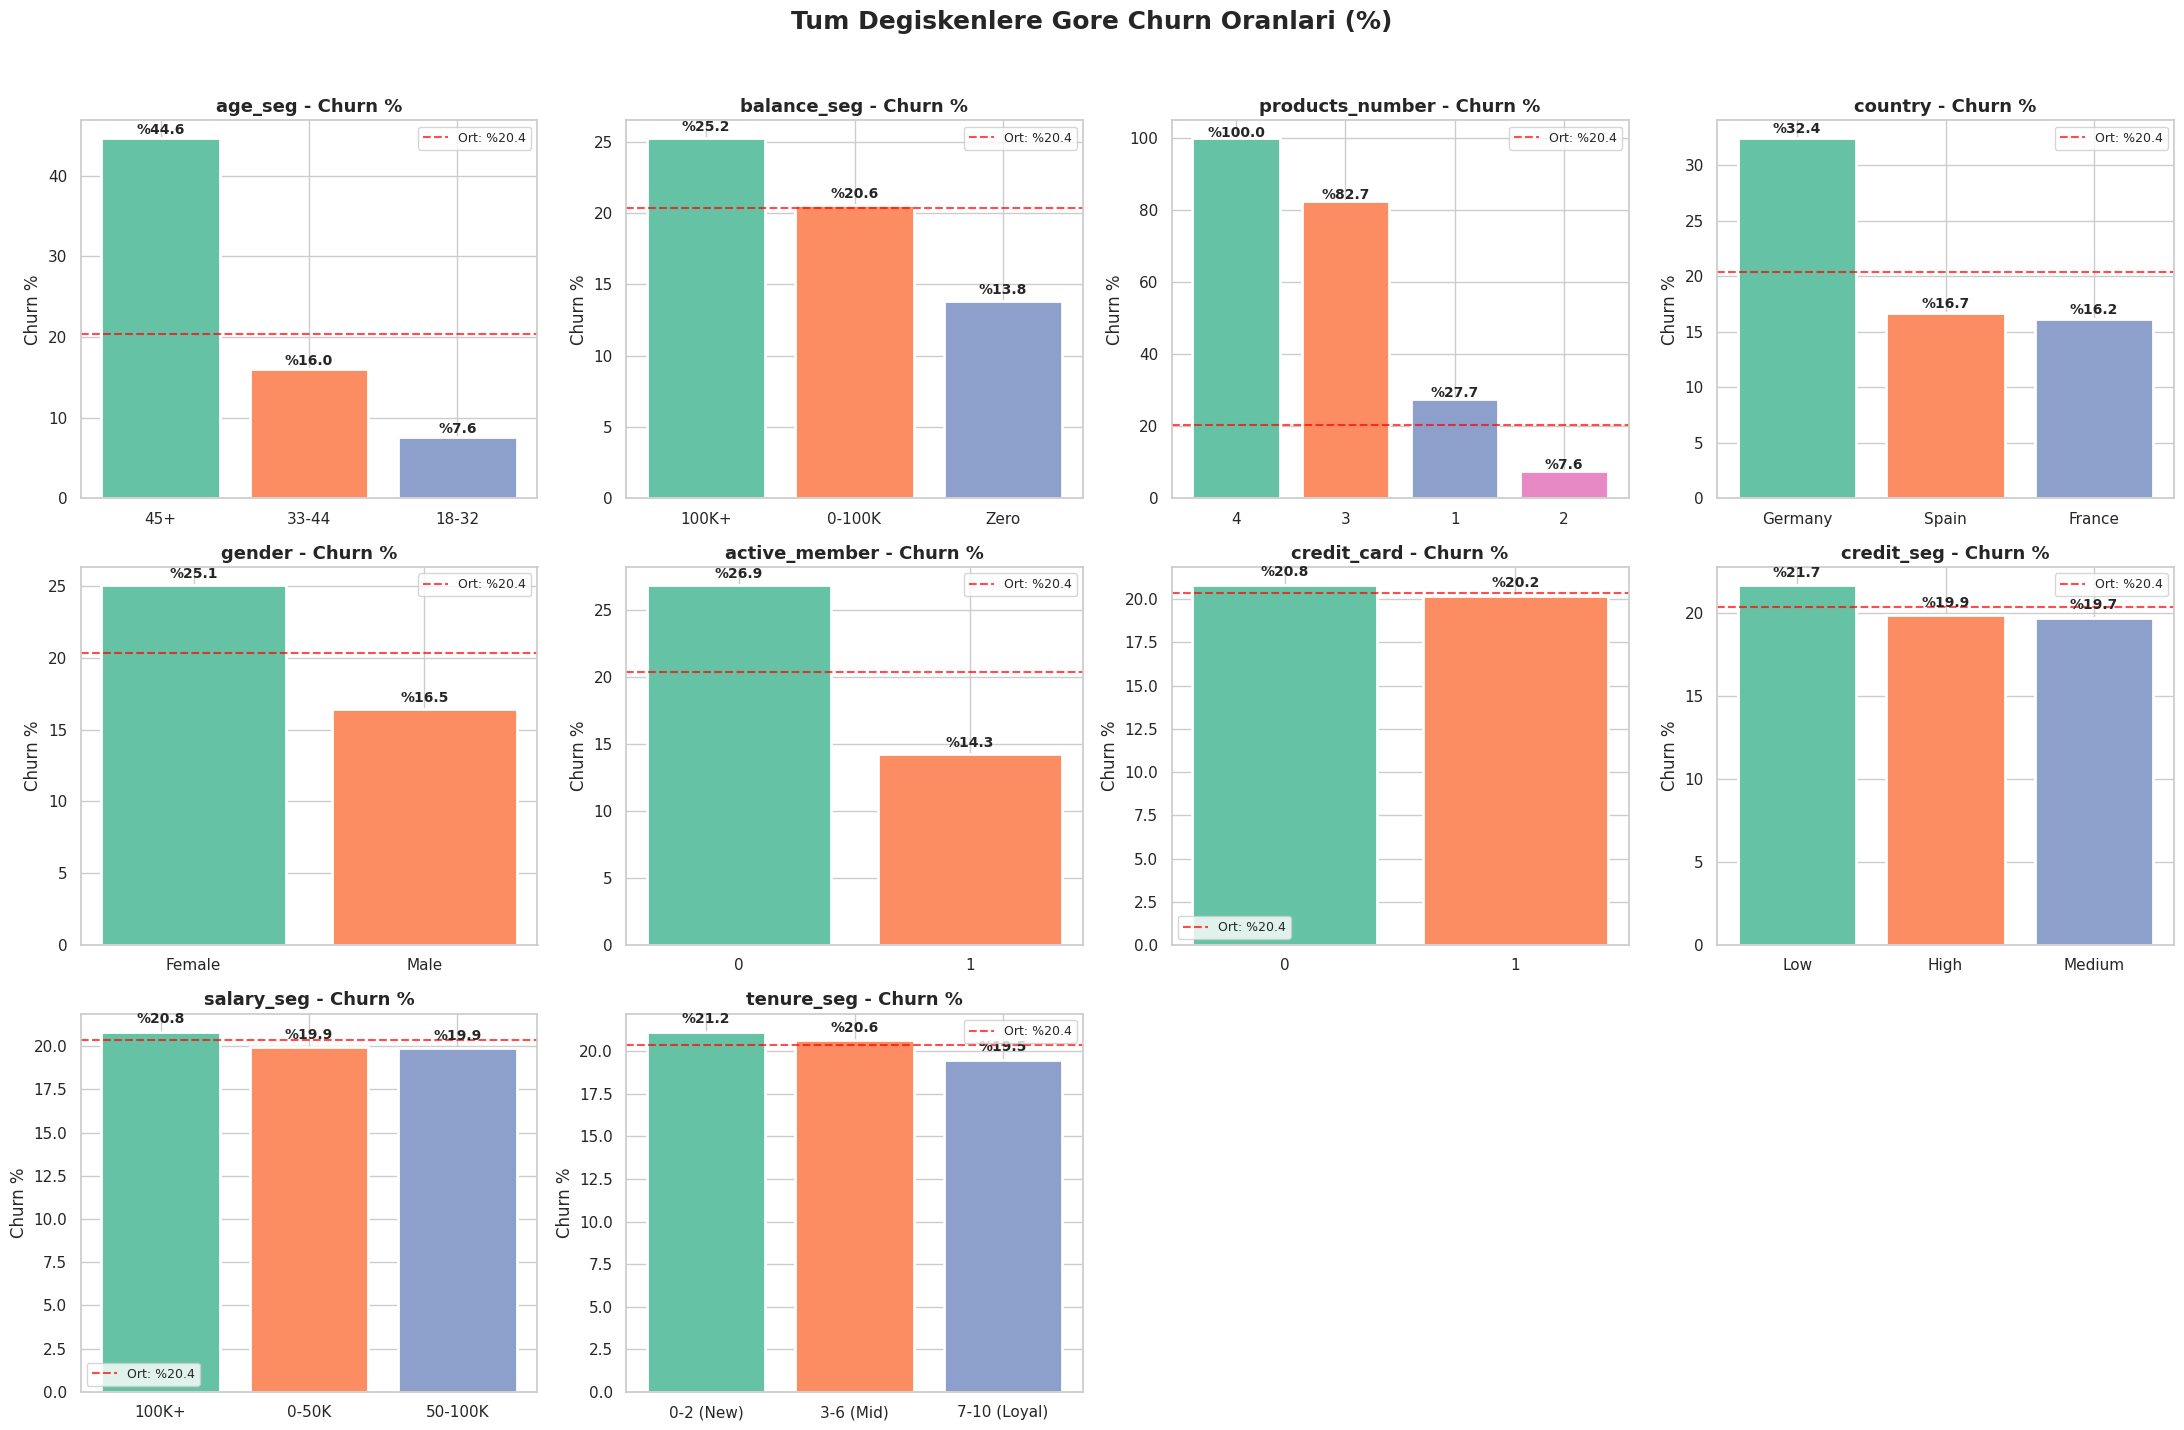

In [59]:
# Sayisal degiskenleri segmentlere ayir
df['age_seg'] = pd.cut(df['age'], bins=[17,32,44,100], labels=['18-32','33-44','45+'])
df['balance_seg'] = pd.cut(df['balance'], bins=[-1,0,100000,300000], labels=['Zero','0-100K','100K+'])
df['credit_seg'] = pd.cut(df['credit_score'], bins=[349,600,700,850], labels=['Low','Medium','High'])
df['salary_seg'] = pd.cut(df['estimated_salary'], bins=[0,50000,100000,200000], labels=['0-50K','50-100K','100K+'])
df['tenure_seg'] = pd.cut(df['tenure'], bins=[-1,2,6,10], labels=['0-2 (New)','3-6 (Mid)','7-10 (Loyal)'])

# Tum degiskenleri ayni formatta goster
all_cols = ['age_seg', 'balance_seg', 'products_number', 'country',
            'gender', 'active_member', 'credit_card', 'credit_seg',
            'salary_seg', 'tenure_seg']

fig, axes = plt.subplots(3, 4, figsize=(22, 14))
axes = axes.flatten()

for i, col in enumerate(all_cols):
    churn_rate = df.groupby(col)['churn'].mean().sort_values(ascending=False)
    bars = axes[i].bar(churn_rate.index.astype(str), churn_rate.values * 100,
                       color=sns.color_palette('Set2', len(churn_rate)), edgecolor='white', linewidth=2)
    axes[i].axhline(y=df['churn'].mean()*100, color='red', linestyle='--', alpha=0.7,
                    label=f'Ort: %{df["churn"].mean()*100:.1f}')
    axes[i].set_title(f'{col} - Churn %', fontsize=13, fontweight='bold')
    axes[i].set_ylabel('Churn %')
    axes[i].legend(fontsize=9)
    for bar, val in zip(bars, churn_rate.values):
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
                    f'%{val*100:.1f}', ha='center', fontweight='bold', fontsize=10)

for j in range(len(all_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Tum Degiskenlere Gore Churn Oranlari (%)', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 10. Feature Secimi

EDA bulgularina dayanarak modelde kullanilacak degiskenlerin belirlenmesi.

**Modele dahil edilecek feature'lar (guclu etki):**
- **age** — Korelasyon: +0.285, en guclu etki
- **active_member** — Korelasyon: -0.156, pasif musteri 2 kat fazla ayriliyor
- **balance** — Korelasyon: +0.119, bakiyesi olan daha cok ayriliyor
- **products_number** — 3+ urunde churn %83-100, en sert ayrim
- **country** — Almanya %32.4 ile digerlerin 2 kati
- **gender** — Kadinlarda %25.1, erkeklerde %16.5

**Modelden cikarilacak degiskenler (etkisiz):**
- **customer_id** — Sadece kimlik numarasi
- **credit_card** — Korelasyon: 0.007, hicbir ayrim yok
- **estimated_salary** — Korelasyon: 0.012, kalan ve ayrilan arasinda fark yok
- **credit_score** — Korelasyon: 0.027, segmentler arasi fark minimal
- **tenure** — Korelasyon: 0.014, neredeyse sifir etki

---
## 11. Veri Hazirlama ve Modelleme

Logistic Regression ile churn tahmini. Iki model karsilastirilacak:
- **Model 1:** Sadece kritik 6 feature
- **Model 2:** Tum 10 feature

### 11.1 Encoding ve Feature Tanimlama

country ve gender kategorik sutunlardir; lojistik regresyon sayisal girdi bekler. `pd.get_dummies()` ile One-Hot Encoding uyguluyoruz.

In [53]:
# One-Hot Encoding
df_enc = pd.get_dummies(df, columns=['country', 'gender'], drop_first=False)

# Kritik featurelar
CRITICAL = ['age', 'active_member', 'balance', 'products_number',
            'country_Germany', 'country_Spain', 'gender_Male']

# Ek featurelar
NON_CRITICAL = ['credit_score', 'tenure', 'estimated_salary', 'credit_card',
                'country_France', 'gender_Female']

ALL_FEATURES = CRITICAL + NON_CRITICAL
TARGET = 'churn'

print(f'Kritik feature sayisi: {len(CRITICAL)}')
print(f'Toplam feature sayisi: {len(ALL_FEATURES)}')

Kritik feature sayisi: 7
Toplam feature sayisi: 13


### 11.2 Train/Test Bolme

Veriyi %80 egitim, %20 test olarak boluyoruz. `stratify=y` ile her iki sette de churn oraninin esit kalmasini sagliyoruz.

In [54]:
X_crit = df_enc[CRITICAL]
X_all = df_enc[ALL_FEATURES]
y = df_enc[TARGET]

X_c_train, X_c_test, y_train, y_test = train_test_split(
    X_crit, y, test_size=0.2, random_state=42, stratify=y
)
X_a_train, X_a_test, _, _ = train_test_split(
    X_all, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Egitim seti: {len(y_train)} satir')
print(f'Test seti  : {len(y_test)} satir')
print(f'Train churn orani: %{y_train.mean()*100:.1f}')
print(f'Test churn orani : %{y_test.mean()*100:.1f}')

Egitim seti: 8000 satir
Test seti  : 2000 satir
Train churn orani: %20.4
Test churn orani : %20.3


### 11.3 Model Egitimi

Pipeline ile StandardScaler + LogisticRegression tek seferde calistirilir. Pipeline kullanmanin avantaji: test setinde sadece egitim verisinin istatistiklerini kullanir — data leakage olmaz.

`class_weight='balanced'`: Churn orani dengesiz (%20 vs %80) oldugu icin ayrilan musterilere daha fazla agirlik verir. Bu olmadan model herkese 'kalan' diyerek %80 accuracy yakalar ama ayrilanlarin %79'unu kacirir.

In [55]:
# Model 1: Sadece kritik featurelar
model_1 = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

# Model 2: Tum featurelar
model_2 = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

model_1.fit(X_c_train, y_train)
model_2.fit(X_a_train, y_train)

print('Her iki model de egitildi.')

Her iki model de egitildi.


### 11.4 Model Karsilastirmasi

In [56]:
# Tahminler
y_pred_c = model_1.predict(X_c_test)
y_pred_a = model_2.predict(X_a_test)
y_prob_c = model_1.predict_proba(X_c_test)[:, 1]
y_prob_a = model_2.predict_proba(X_a_test)[:, 1]

# 5-Fold Cross Validation AUC
cv_c = cross_val_score(model_1, X_crit, y, cv=5, scoring='roc_auc')
cv_a = cross_val_score(model_2, X_all, y, cv=5, scoring='roc_auc')

results = pd.DataFrame({
    'Metrik': ['Accuracy', 'AUC-ROC (test)', 'CV AUC (5-fold mean)', 'CV AUC Std'],
    'Model 1 — Kritik': [
        f'{accuracy_score(y_test, y_pred_c):.4f}',
        f'{roc_auc_score(y_test, y_prob_c):.4f}',
        f'{cv_c.mean():.4f}',
        f'{cv_c.std():.4f}'
    ],
    'Model 2 — Tum': [
        f'{accuracy_score(y_test, y_pred_a):.4f}',
        f'{roc_auc_score(y_test, y_prob_a):.4f}',
        f'{cv_a.mean():.4f}',
        f'{cv_a.std():.4f}'
    ]
})
results

,Metrik,Model 1 — Kritik,Model 2 — Tum
0,Accuracy,0.7180,0.7135
1,AUC-ROC (test),0.7793,0.7771
2,CV AUC (5-fold mean),0.7689,0.7691
3,CV AUC Std,0.0114,0.0105


Model 1 (kritik featurelar) ile Model 2 (tum featurelar) arasinda anlamli bir performans farki yok. Daha yorumlanabilir ve bakim kolay oldugu icin **Model 1 tercih edilmelidir.**

---
## 12. Model Degerlendirme (Model 1)

### 12.1 Feature Importance (Katsayilar)

In [32]:
importance = pd.DataFrame({
    'Feature': CRITICAL,
    'Coefficient': model_1.named_steps['lr'].coef_[0]
})
importance['Impact'] = importance['Coefficient'].abs()
importance = importance.sort_values(by='Impact', ascending=False)
importance

,Feature,Coefficient,Impact
0,age,0.80,0.80
1,active_member,-0.44,0.44
4,country_Germany,0.36,0.36
6,gender_Male,-0.27,0.27
2,balance,0.18,0.18
3,products_number,-0.06,0.06
5,country_Spain,0.02,0.02


### 12.2 Tahmin Dagilimi

In [33]:
y_pred = model_1.predict(X_c_test)
y_prob = model_1.predict_proba(X_c_test)[:, 1]

kalacak = (y_pred == 0).sum()
ayrilacak = (y_pred == 1).sum()

print('=== TAHMIN DAGILIMI ===')
print(f'Kalacak tahmini   : {kalacak}  ({kalacak/len(y_pred):.1%})')
print(f'Ayrilacak tahmini : {ayrilacak} ({ayrilacak/len(y_pred):.1%})')
print(f'\nAccuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'AUC-ROC  : {roc_auc_score(y_test, y_prob):.4f}')

=== TAHMIN DAGILIMI ===
Kalacak tahmini   : 1265  (63.2%)
Ayrilacak tahmini : 735 (36.8%)

Accuracy : 0.7180
AUC-ROC  : 0.7793


### 12.3 Confusion Matrix

=== CONFUSION MATRIX ===
True Negative  (TN) = 1147  - Dogru "kalacak" tahmini
False Positive (FP) = 446   - Yanlis "ayrilacak" tahmini
False Negative (FN) = 118  - Kacirilan churn
True Positive  (TP) = 289   - Dogru yakalanan churn


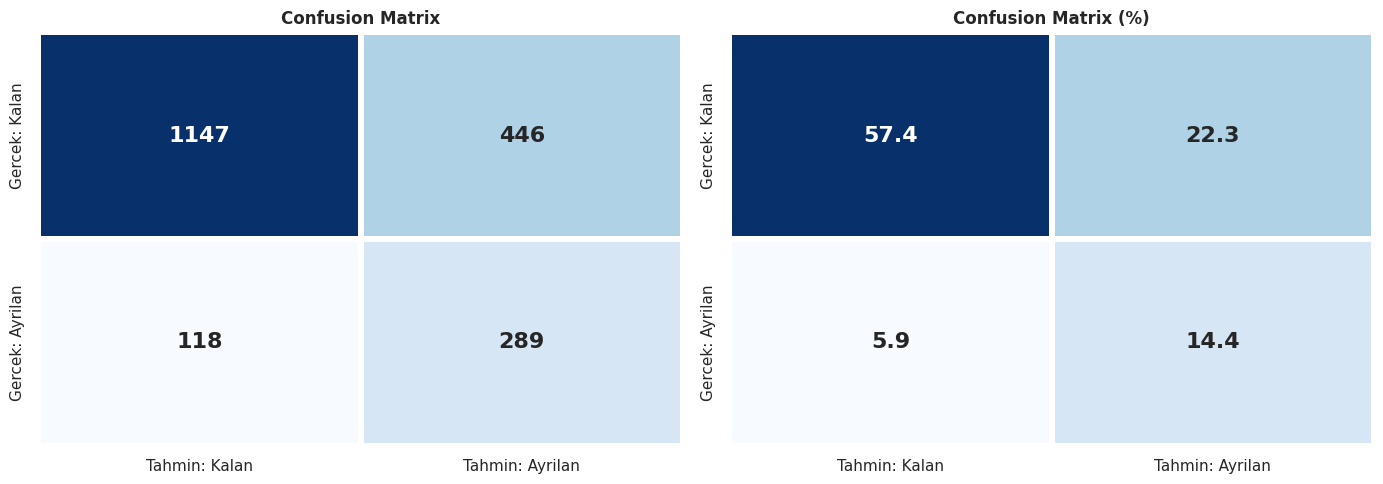

In [34]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('=== CONFUSION MATRIX ===')
print(f'True Negative  (TN) = {tn}  - Dogru "kalacak" tahmini')
print(f'False Positive (FP) = {fp}   - Yanlis "ayrilacak" tahmini')
print(f'False Negative (FN) = {fn}  - Kacirilan churn')
print(f'True Positive  (TP) = {tp}   - Dogru yakalanan churn')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sayisal heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Tahmin: Kalan', 'Tahmin: Ayrilan'],
            yticklabels=['Gercek: Kalan', 'Gercek: Ayrilan'],
            cbar=False, linewidths=3, linecolor='white',
            annot_kws={'size': 16, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix', fontweight='bold')

# Yuzde heatmap
cm_pct = cm / cm.sum() * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            xticklabels=['Tahmin: Kalan', 'Tahmin: Ayrilan'],
            yticklabels=['Gercek: Kalan', 'Gercek: Ayrilan'],
            cbar=False, linewidths=3, linecolor='white',
            annot_kws={'size': 16, 'weight': 'bold'})
axes[1].set_title('Confusion Matrix (%)', fontweight='bold')

plt.tight_layout()
plt.show()

### 12.4 Classification Report

In [35]:
print(classification_report(y_test, y_pred, target_names=['Kalan (0)', 'Ayrilan (1)']))

report = classification_report(y_test, y_pred, target_names=['Kalan (0)', 'Ayrilan (1)'], output_dict=True)

print('=== CHURN SINIFI (Ayrilan=1) ===')
print(f'Precision : {report["Ayrilan (1)"]["precision"]:.3f}')
print(f'Recall    : {report["Ayrilan (1)"]["recall"]:.3f}')
print(f'F1-Score  : {report["Ayrilan (1)"]["f1-score"]:.3f}')

              precision    recall  f1-score   support

   Kalan (0)       0.91      0.72      0.80      1593
 Ayrilan (1)       0.39      0.71      0.51       407

    accuracy                           0.72      2000
   macro avg       0.65      0.72      0.65      2000
weighted avg       0.80      0.72      0.74      2000

=== CHURN SINIFI (Ayrilan=1) ===
Precision : 0.393
Recall    : 0.710
F1-Score  : 0.506


### 12.5 ROC Egrisi

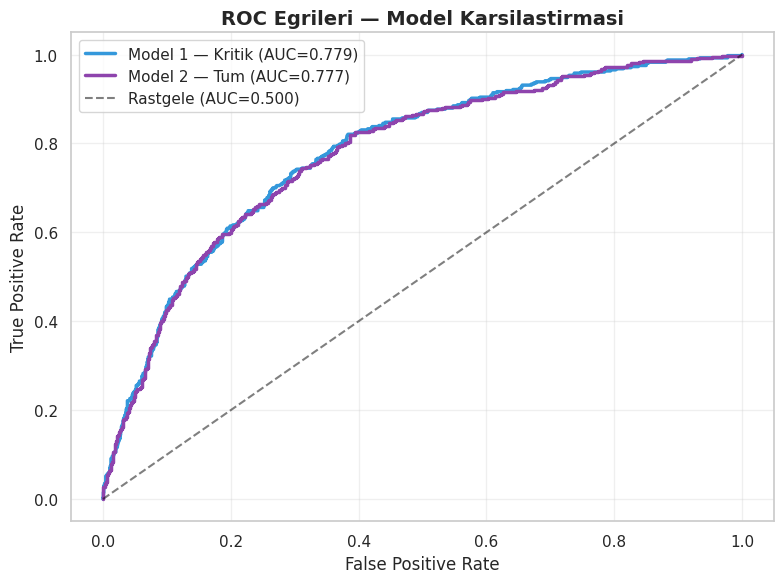

In [36]:
fig, ax = plt.subplots(figsize=(8, 6))

for prob, label, color in [
    (y_prob_c, 'Model 1 — Kritik', '#3498DB'),
    (y_prob_a, 'Model 2 — Tum', '#8E44AD')
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, lw=2.5, color=color, label=f'{label} (AUC={auc:.3f})')

ax.plot([0,1], [0,1], 'k--', alpha=0.5, label='Rastgele (AUC=0.500)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Egrileri — Model Karsilastirmasi', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## 13. Risk Segmentasyonu

`predict_proba()` her musteri icin churn olasiligi dondurur (0-1 arasi). Bu olasiliga gore musterileri 3 segmente ayiriyoruz:
- **High Risk:** Olasilik >= 0.50
- **Medium Risk:** 0.25 <= Olasilik < 0.50
- **Low Risk:** Olasilik < 0.25

In [37]:
# Tum musterilere churn olasiligi ata
df_seg = df_enc.copy()
df_seg['churn_prob'] = model_2.predict_proba(df_enc[ALL_FEATURES])[:, 1]

def assign_segment(prob):
    if prob >= 0.50:
        return 'High Risk'
    elif prob >= 0.25:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df_seg['segment'] = df_seg['churn_prob'].apply(assign_segment)

seg_stats = df_seg.groupby('segment').agg(
    Musteri_Sayisi=('churn_prob', 'count'),
    Ort_Churn_Prob=('churn_prob', 'mean'),
    Gercek_Churn=('churn', 'mean'),
    Ort_Yas=('age', 'mean'),
    Aktif_Oran=('active_member', 'mean'),
    Ort_Urun=('products_number', 'mean')
).round(2)

seg_stats

,Musteri_Sayisi,Ort_Churn_Prob,Gercek_Churn,Ort_Yas,Aktif_Oran,Ort_Urun
segment,,,,,,
High Risk,3652,0.68,0.38,47.17,0.33,1.46
Low Risk,2370,0.17,0.05,30.55,0.85,1.62
Medium Risk,3978,0.37,0.13,36.34,0.49,1.54


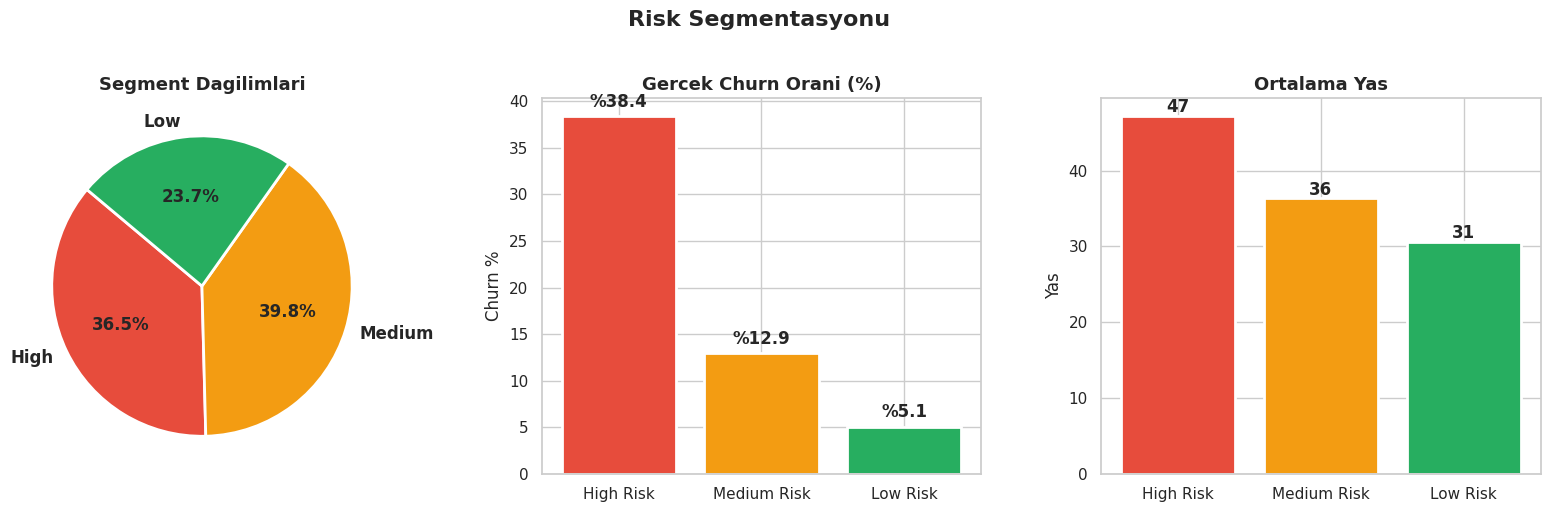

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
PALETTE = {'High Risk': '#E74C3C', 'Medium Risk': '#F39C12', 'Low Risk': '#27AE60'}
seg_order = ['High Risk', 'Medium Risk', 'Low Risk']

# Pasta: Segment buyuklukleri
counts = df_seg['segment'].value_counts()
axes[0].pie(
    [counts.get(s, 0) for s in seg_order],
    labels=['High', 'Medium', 'Low'],
    colors=[PALETTE[s] for s in seg_order],
    autopct='%1.1f%%', startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops={'fontweight': 'bold', 'fontsize': 12})
axes[0].set_title('Segment Dagilimlari', fontweight='bold', fontsize=13)

# Bar: Gercek churn oranlari
churn_by_seg = df_seg.groupby('segment')['churn'].mean().reindex(seg_order)
bars = axes[1].bar(seg_order, churn_by_seg.values * 100,
       color=[PALETTE[s] for s in seg_order], edgecolor='white', linewidth=2)
for bar, val in zip(bars, churn_by_seg.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'%{val*100:.1f}', ha='center', fontweight='bold', fontsize=12)
axes[1].set_title('Gercek Churn Orani (%)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Churn %')

# Bar: Ortalama yas
age_by_seg = df_seg.groupby('segment')['age'].mean().reindex(seg_order)
bars2 = axes[2].bar(seg_order, age_by_seg.values,
        color=[PALETTE[s] for s in seg_order], edgecolor='white', linewidth=2)
for bar, val in zip(bars2, age_by_seg.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val:.0f}', ha='center', fontweight='bold', fontsize=12)
axes[2].set_title('Ortalama Yas', fontweight='bold', fontsize=13)
axes[2].set_ylabel('Yas')

plt.suptitle('Risk Segmentasyonu', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 14. Sonuc ve Is Onerileri

### Model Performansi

| Metrik | Deger | Yorum |
|--------|-------|-------|
| Accuracy | ~0.72 | Genel dogruluk |
| AUC-ROC | ~0.78 | Orta-iyi ayirt etme gucu |
| Recall (Churn) | ~0.71 | Ayrilanlarin %71'i yakalandi |
| Precision (Churn) | ~0.39 | Yanlis alarm orani yuksek |

### Temel Bulgular

1. **Churn orani %20.4** — Her 5 musteriden 1'i bankadan ayriliyor
2. **Yas en guclu faktor** — 45+ yas grubunda churn %44.6
3. **Urun sayisi kritik** — 2 urunlu musteriler en sadik (%7.6), 3+ urunlulerde churn %83-100
4. **Pasif musteriler riskli** — Aktif olmayanlarda churn 2 kat fazla
5. **Almanya en riskli ulke** — %32.4 churn ile digerlerin 2 kati
6. **Kadin musteriler** erkeklere gore 1.5 kat daha fazla ayriliyor
7. **Credit score, tenure, salary, credit card** — Churn uzerinde anlamli etkisi yok
8. Model 1 (kritik featurelar) ile Model 2 (tum featurelar) arasinda anlamli performans farki yok

### En Yuksek Riskli Musteri Profili

Yasli (45+), Almanya'da, 3+ urunu olan, aktif olmayan kadin musteri.

### Aksiyon Onerileri

- **High Risk segment:** Acil retention kampanyasi — kisisellestirilmis teklifler, sadakat programlari
- **Almanya operasyonlari:** Hizmet kalitesi ve rekabet analizi yapilmali
- **Pasif musteriler:** Yeniden aktivasyon kampanyalari
- **3+ urunlu musteriler:** Urun memnuniyet anketi, gereksiz urunleri sadelelestirme
- **45+ yas grubu:** Yas grubuna ozel urun ve hizmet tasarimi